In [113]:
import csv
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from boruta import BorutaPy
from sklearn.svm import SVR
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [114]:
df = pd.read_csv('NASA_2021_2023.csv')
df

,YEAR,MO,DY,HR,ALLSKY_SFC_SW_DWN,T2M,RH2M,PS,WS10M,WD10M
0,2021,1,1,0,0.0,12.25,80.12,98.24,3.56,355.09
1,2021,1,1,1,0.0,11.83,86.44,98.27,3.82,350.46
2,2021,1,1,2,0.0,11.47,93.25,98.26,4.10,348.00
3,2021,1,1,3,0.0,11.16,100.00,98.26,4.26,347.06
4,2021,1,1,4,0.0,10.92,100.00,98.28,4.40,345.72
...,...,...,...,...,...,...,...,...,...,...
26299,2024,1,1,19,0.0,14.56,75.81,98.59,4.58,332.61
26300,2024,1,1,20,0.0,14.26,79.94,98.62,4.65,335.93
26301,2024,1,1,21,0.0,14.50,80.25,98.64,4.62,342.36
26302,2024,1,1,22,0.0,14.24,81.56,98.64,4.61,348.96


In [115]:
df['All Sky Surface Shortwave Downward Irradiance'] = df['ALLSKY_SFC_SW_DWN']
df['Temperature at 2 Meters'] = df['T2M']
df['Relative Humidity at 2 Meters'] = df['RH2M']
df['Surface Pressure'] = df['PS']
df['Wind Speed at 10 Meters'] = df['WS10M']
df['Wind Direction at 10 Meters'] = df['WD10M']

df = df.drop(columns=['ALLSKY_SFC_SW_DWN', 'T2M', 'RH2M', 'PS', 'WS10M', 'WD10M'])
df

,YEAR,MO,DY,HR,All Sky Surface Shortwave Downward Irradiance,Temperature at 2 Meters,Relative Humidity at 2 Meters,Surface Pressure,Wind Speed at 10 Meters,Wind Direction at 10 Meters
0,2021,1,1,0,0.0,12.25,80.12,98.24,3.56,355.09
1,2021,1,1,1,0.0,11.83,86.44,98.27,3.82,350.46
2,2021,1,1,2,0.0,11.47,93.25,98.26,4.10,348.00
3,2021,1,1,3,0.0,11.16,100.00,98.26,4.26,347.06
4,2021,1,1,4,0.0,10.92,100.00,98.28,4.40,345.72
...,...,...,...,...,...,...,...,...,...,...
26299,2024,1,1,19,0.0,14.56,75.81,98.59,4.58,332.61
26300,2024,1,1,20,0.0,14.26,79.94,98.62,4.65,335.93
26301,2024,1,1,21,0.0,14.50,80.25,98.64,4.62,342.36
26302,2024,1,1,22,0.0,14.24,81.56,98.64,4.61,348.96


### Anova Feature Selection

Selected feature names: ['Temperature at 2 Meters', 'Relative Humidity at 2 Meters', 'Wind Speed at 10 Meters', 'Surface Pressure', 'YEAR']
the number of features:  5
Seelcted Features Scores:  [('Temperature at 2 Meters', 1.8568203592568095), ('Relative Humidity at 2 Meters', 1.7480596050413086), ('Wind Speed at 10 Meters', 1.7164696948033584), ('Surface Pressure', 1.0991259739856283), ('YEAR', 1.001673859643414)]


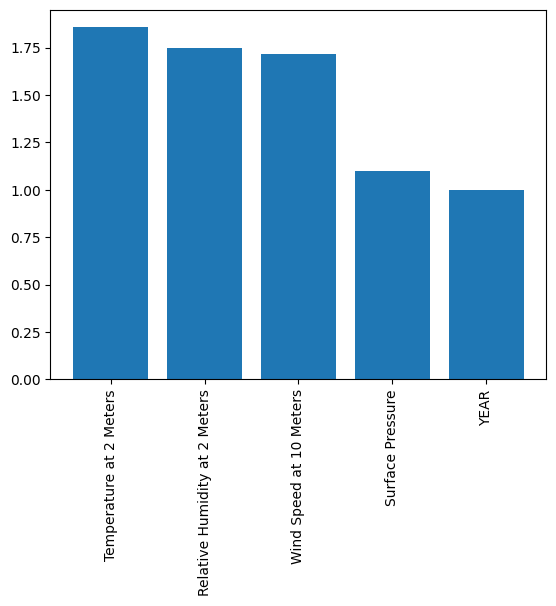

In [116]:
X = df.drop(columns=['All Sky Surface Shortwave Downward Irradiance', 'MO'])
y = df['All Sky Surface Shortwave Downward Irradiance']

selector = SelectKBest(f_classif, k=5)  # Select top 9 features
X_new = selector.fit_transform(X, y)
scores = selector.scores_
selected_feature_indices = selector.get_support(indices=True)
selected_features_with_scores = [(X.columns[i], scores[i]) for i in selected_feature_indices]
selected_features_with_scores.sort(key=lambda x: x[1], reverse=True)
sorted_selected_feature_names = [feature[0] for feature in selected_features_with_scores]
#selected_feature_names = X.columns[selected_feature_indices]
print("Selected feature names:", sorted_selected_feature_names)
print("the number of features: ", len(sorted_selected_feature_names))
print("Seelcted Features Scores: ", selected_features_with_scores)

plt.bar([feature[0] for feature in selected_features_with_scores], [feature[1] for feature in selected_features_with_scores])
plt.xticks(rotation=90)
plt.show()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

### Boruta Feature Selection

In [ ]:
model = RandomForestRegressor()
boruta_selector = BorutaPy(model, n_estimators='auto', verbose=0, random_state=1, max_iter=100)
boruta_selector.fit(X.values, y.values)
print("Boruta Ranking: ", boruta_selector.ranking_)
print("No. of significant features: ", boruta_selector.n_features_)
selected_rf_features = pd.DataFrame({
    'Feature': list(X.columns),
    'Ranking': boruta_selector.ranking_
}).sort_values(by='Ranking')
# Selecting the columns with ranking 1
new_columns = selected_rf_features[selected_rf_features["Ranking"] == 1]['Feature']
X_new = X[new_columns]

plt.bar(selected_rf_features['Feature'], selected_rf_features['Ranking'])
plt.xticks(rotation=90)
plt.grid()
plt.title("Feature Selection Based on Boruta")
plt.xlabel("Features")
plt.ylabel("Ranking")
plt.show()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

In [117]:
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f'MSE: {mse}')
print(f'RMSE: {rmse}')
print(f'R2: {r2}')
print(f'MAE: {mae}')

MSE: 47648.08112534611
RMSE: 218.28440421923437
R2: 0.5684498739375015
MAE: 178.18928895331737


In [118]:
gb = GradientBoostingRegressor()
gb.fit(X_train, y_train)
y_pred = gb.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f'MSE: {mse}')
print(f'RMSE: {rmse}')
print(f'R2: {r2}')
print(f'MAE: {mae}')

MSE: 3755.6672212889744
RMSE: 61.28349876833873
R2: 0.9659848072678441
MAE: 38.31153191857503


In [119]:
dt = DecisionTreeRegressor()
dt.fit(X_train, y_train)
y_pred = dt.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f'MSE: {mse}')
print(f'RMSE: {rmse}')
print(f'R2: {r2}')
print(f'MAE: {mae}')

MSE: 5540.733443204714
RMSE: 74.43610308986301
R2: 0.9498174079748668
MAE: 35.15658049800418


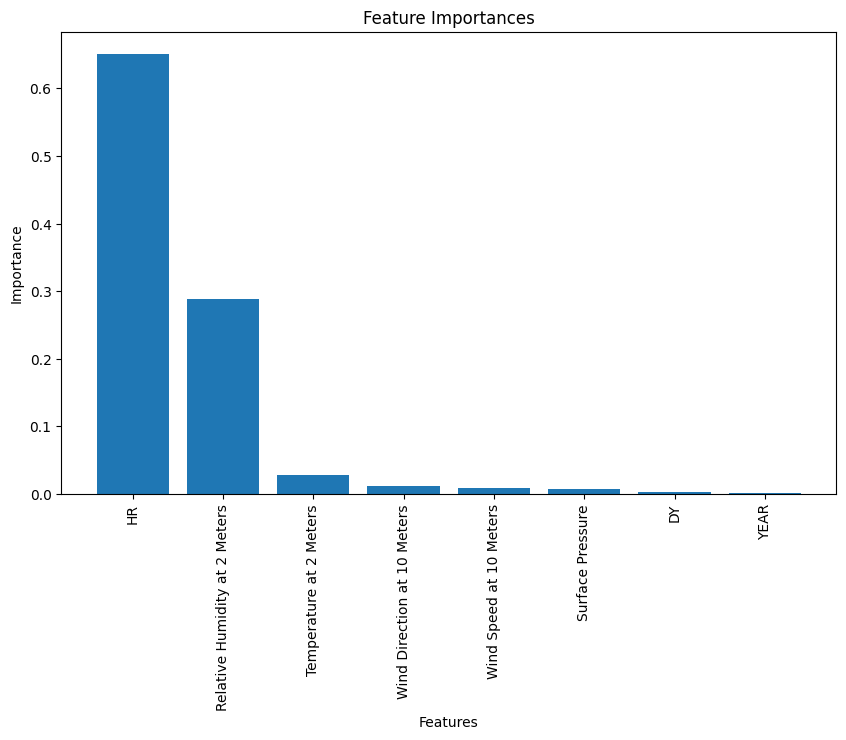

MSE: 2585.86471842588
RMSE: 50.85139839203913
R2: 0.9765797442654276
MAE: 26.109969540011406


In [120]:
rf = RandomForestRegressor()
rf.fit(X_train, y_train)
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]
features = X.columns

plt.figure(figsize=(10, 6))
plt.title('Feature Importances')
plt.bar(range(X.shape[1]), importances[indices], align='center')
plt.xticks(range(X.shape[1]), [features[i] for i in indices], rotation=90)
plt.xlabel('Features')
plt.ylabel('Importance')
plt.show()
y_pred = rf.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f'MSE: {mse}')
print(f'RMSE: {rmse}')
print(f'R2: {r2}')
print(f'MAE: {mae}')

In [121]:
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5, random_state=42)
print(X_train.shape, X_val.shape, X_test.shape)

(15782, 8) (5261, 8) (5261, 8)


In [122]:
early_stopping = tf.keras.callbacks.EarlyStopping(patience=2, monitor='val_loss')

X_train = np.expand_dims(X_train, axis=1)
X_test = np.expand_dims(X_test, axis=1)
X_val = np.expand_dims(X_val, axis=1)
model = tf.keras.models.Sequential([
    tf.keras.layers.Conv1D(64, 3, activation='relu',padding='same', input_shape=(X_train.shape[1], X_train.shape[2])),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(1, activation='linear'),
])

model.compile(optimizer='adam', loss='mse')

model.fit(X_train, y_train, epochs=1000, batch_size=32, validation_data=(X_test, y_test), callbacks=[early_stopping])

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"MSE: {mse}")
print(f"RMSE: {rmse}")
print(f"R2: {r2}")
print(f"MAE: {mae}")

Epoch 1/1000


494/494 [==============================] - 3s 5ms/step - loss: 104068.3672 - val_loss: 94073.4297
Epoch 2/1000
494/494 [==============================] - 3s 6ms/step - loss: 81303.7578 - val_loss: 73127.8438
Epoch 3/1000
494/494 [==============================] - 3s 6ms/step - loss: 68842.3984 - val_loss: 65847.5391
Epoch 4/1000
494/494 [==============================] - 3s 5ms/step - loss: 64808.9961 - val_loss: 62743.6836
Epoch 5/1000
494/494 [==============================] - 2s 4ms/step - loss: 62204.2500 - val_loss: 60581.6328
Epoch 6/1000
494/494 [==============================] - 2s 4ms/step - loss: 60490.2344 - val_loss: 60269.3516
Epoch 7/1000
494/494 [==============================] - 2s 4ms/step - loss: 59403.0742 - val_loss: 58227.6758
Epoch 8/1000
494/494 [==============================] - 2s 4ms/step - loss: 58451.2461 - val_loss: 58007.9180
Epoch 9/1000
494/494 [==============================] - 3s 5ms/step - loss: 57697.8867 - val_loss: 56265.1055
Epoch 10/1000
494/494 

In [123]:
model_lstm = tf.keras.models.Sequential([
    tf.keras.layers.LSTM(32, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=True),
    tf.keras.layers.Dense(1, activation='linear'),
])

model_lstm.compile(optimizer='adam', loss='mse')

model_lstm.fit(X_train, y_train, epochs=1000, batch_size=32, validation_data=(X_test, y_test), callbacks=[early_stopping])

y_pred = model_lstm.predict(X_test)
y_pred = np.squeeze(y_pred)
y_pred = np.squeeze(y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"MSE: {mse}")
print(f"RMSE: {rmse}")
print(f"R2: {r2}")
print(f"MAE: {mae}")

Epoch 1/1000
494/494 [==============================] - 6s 9ms/step - loss: 109821.3594 - val_loss: 108650.9531
Epoch 2/1000
494/494 [==============================] - 5s 9ms/step - loss: 105611.3516 - val_loss: 104399.8516
Epoch 3/1000
494/494 [==============================] - 4s 9ms/step - loss: 100412.1094 - val_loss: 97859.7188
Epoch 4/1000
494/494 [==============================] - 4s 9ms/step - loss: 93097.9141 - val_loss: 89403.8984
Epoch 5/1000
494/494 [==============================] - 4s 9ms/step - loss: 84697.8125 - val_loss: 80972.4766
Epoch 6/1000
494/494 [==============================] - 4s 9ms/step - loss: 77051.2031 - val_loss: 74112.8906
Epoch 7/1000
494/494 [==============================] - 4s 9ms/step - loss: 71586.1875 - val_loss: 69784.4531
Epoch 8/1000
494/494 [==============================] - 4s 9ms/step - loss: 68043.4922 - val_loss: 66663.7188
Epoch 9/1000
494/494 [==============================] - 4s 9ms/step - loss: 65651.6172 - val_loss: 64571.6680
Epoch

In [124]:
early_stopping = tf.keras.callbacks.EarlyStopping(patience=2, monitor='val_loss')

model_cnn_lstm = tf.keras.models.Sequential([
    tf.keras.layers.Conv1D(64, 3, activation='relu',padding='same', input_shape=(X_train.shape[1], X_train.shape[2])),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Flatten()),
    tf.keras.layers.LSTM(32, activation='relu', return_sequences=True),
    tf.keras.layers.Dense(1, activation='linear'),
])

model_cnn_lstm.compile(optimizer='adam', loss='mse')

model_cnn_lstm.fit(X_train, y_train, epochs=1000, batch_size=32, validation_data=(X_test, y_test), callbacks=[early_stopping])

y_pred = model_cnn_lstm.predict(X_test)
y_pred = np.squeeze(y_pred)
y_pred = np.squeeze(y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"MSE: {mse}")
print(f"RMSE: {rmse}")
print(f"R2: {r2}")
print(f"MAE: {mae}")

Epoch 1/1000
494/494 [==============================] - 7s 10ms/step - loss: 112298.4297 - val_loss: 108218.6953
Epoch 2/1000
494/494 [==============================] - 5s 10ms/step - loss: 93365.3906 - val_loss: 72363.3828
Epoch 3/1000
494/494 [==============================] - 5s 10ms/step - loss: 67504.6172 - val_loss: 63339.1680
Epoch 4/1000
494/494 [==============================] - 5s 9ms/step - loss: 60954.7266 - val_loss: 58629.3477
Epoch 5/1000
494/494 [==============================] - 5s 9ms/step - loss: 58383.8984 - val_loss: 56438.1289
Epoch 6/1000
494/494 [==============================] - 5s 9ms/step - loss: 56030.1445 - val_loss: 55584.2070
Epoch 7/1000
494/494 [==============================] - 5s 10ms/step - loss: 54432.0781 - val_loss: 53311.2266
Epoch 8/1000
494/494 [==============================] - 5s 9ms/step - loss: 53587.9961 - val_loss: 50931.1367
Epoch 9/1000
494/494 [==============================] - 5s 9ms/step - loss: 52237.4180 - val_loss: 51016.5430
Epoc

### From 1/1/2024 to 1/2/2024 predictions

In [125]:
df_test = pd.read_csv('Test2_POWER_Point_Hourly_20240101_20240201_029d20N_032d62E_LST.csv')
df_test['All Sky Surface Shortwave Downward Irradiance'] = df_test['ALLSKY_SFC_SW_DWN']
df_test['Temperature at 2 Meters'] = df_test['T2M']
df_test['Relative Humidity at 2 Meters'] = df_test['RH2M']
df_test['Surface Pressure'] = df_test['PS']
df_test['Wind Speed at 10 Meters'] = df_test['WS10M']
df_test['Wind Direction at 10 Meters'] = df_test['WD10M']

df_test = df_test.drop(columns=['ALLSKY_SFC_SW_DWN', 'T2M', 'RH2M', 'PS', 'WS10M', 'WD10M'])
df_test = df_test.drop(columns=['MO'])
df_test.head()

,YEAR,DY,HR,All Sky Surface Shortwave Downward Irradiance,Temperature at 2 Meters,Relative Humidity at 2 Meters,Surface Pressure,Wind Speed at 10 Meters,Wind Direction at 10 Meters
0,2024,1,0,0.0,12.83,95.50,98.64,3.96,9.54
1,2024,1,1,0.0,12.87,96.31,98.63,3.78,9.40
2,2024,1,2,0.0,12.87,96.50,98.62,3.83,8.10
3,2024,1,3,0.0,12.83,97.19,98.61,4.01,8.51
4,2024,1,4,0.0,12.83,97.81,98.62,4.19,8.15


In [126]:
#list_prediction = []
#for i in range(len(df_test)):
#    prediction = rf.predict([df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance").iloc[i]])
#    list_prediction.append(prediction[0])

y_pred_lr = lr.predict(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"))
y_pred_gb = gb.predict(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"))
y_pred_dt = dt.predict(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"))
y_pred_rf = rf.predict(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"))
y_pred_cnn = model.predict(np.expand_dims(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"), axis=1))
y_pred_lstm = model_lstm.predict(np.expand_dims(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"), axis=1))
y_pred_cnn_lstm = model_cnn_lstm.predict(np.expand_dims(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"), axis=1))
y_pred_cnn = np.squeeze(y_pred_cnn)
y_pred_lstm = np.squeeze(y_pred_lstm)
y_pred_cnn_lstm = np.squeeze(y_pred_cnn_lstm)
y_pred_cnn_lstm = np.squeeze(y_pred_cnn_lstm)

pred = [y_pred_lr, y_pred_gb, y_pred_dt, y_pred_rf, y_pred_cnn, y_pred_lstm, y_pred_cnn_lstm]
for i in range(len(pred)):
    r2 = r2_score(df_test['All Sky Surface Shortwave Downward Irradiance'], pred[i])
    mse = mean_squared_error(df_test['All Sky Surface Shortwave Downward Irradiance'], pred[i])
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(df_test['All Sky Surface Shortwave Downward Irradiance'], pred[i])
    print(f"R2 {i}: {r2}")
    print(f"MSE {i}: {mse}")
    print(f"RMSE {i}: {rmse}")
    print(f"MAE {i}: {mae}")


#df_test['Predicted All Sky Surface Shortwave Downward Irradiance'] = list_prediction
#df_test['Actuall All Sky Surface Shortwave Downward Irradiance'] = df_test['All Sky Surface Shortwave Downward Irradiance']
#df_test = df_test.drop(columns='All Sky Surface Shortwave Downward Irradiance')
#df_test.to_csv('DecisionTree_Predicted_POWER.csv', index=False)

 1/24 [>.............................] - ETA: 0s

24/24 [==============================] - 0s 3ms/step
R2 0: 0.5916436271471515
MSE 0: 23226.937410551105
RMSE 0: 152.40386284655355
MAE 0: 122.75756856448999
R2 1: 0.9249650675901572
MSE 1: 4267.918403018001
RMSE 1: 65.32930738204716
MAE 1: 40.33998058806528
R2 2: 0.8737345781741254
MSE 2: 7181.8618364583335
RMSE 2: 84.74586619097319
MAE 2: 40.07671875
R2 3: 0.9449268386883237
MSE 3: 3132.5111001719138
RMSE 3: 55.96884043976535
MAE 3: 26.87202486979166
R2 4: 0.31916576420224796
MSE 4: 38725.22931712212
RMSE 4: 196.78726919473758
MAE 4: 145.58660937198206
R2 5: 0.4548126328690003
MSE 5: 31009.75935531195
RMSE 5: 176.09588114238207
MAE 5: 112.94261641753526
R2 6: 0.751549144566747
MSE 6: 14131.657670555176
RMSE 6: 118.87664897091933
MAE 6: 98.21535806813587
